# Notebook 06 - Model Comparison Benchmark

This notebook benchmarks **3 models** on the same SAR flood detection dataset:

| Model | Type |
|---|---|
| Random Forest | Traditional ML |
| XGBoost | Gradient Boosting |
| Simple CNN | Deep Learning |

**Metrics:** Accuracy, Precision, Recall, F1-Score, Training Time

## Step 1: Imports & Feature Preparation

In [1]:
import os, sys
# Set project root path cleanly
ROOT_DIR = os.path.abspath('..') if os.path.exists('../config.json') else os.path.abspath('.')
if ROOT_DIR not in sys.path:
    sys.path.insert(0, ROOT_DIR)

import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd
from dataset import Sen1FloodsDataset, get_train_val_test_splits
from models import ConvAutoencoder
from utils import set_seed, load_config

try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False

config = load_config(os.path.join(ROOT_DIR, 'config.json'))
set_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
TARGET_SIZE = tuple(config['data']['target_size'])

plt.rcParams['figure.facecolor'] = '#0d1117'
plt.rcParams['axes.facecolor'] = '#161b22'
plt.rcParams['text.color'] = 'white'
plt.rcParams['axes.labelcolor'] = 'white'
plt.rcParams['xtick.color'] = 'white'
plt.rcParams['ytick.color'] = 'white'

print(f'Device: {device}')


Device: cpu


## Step 2: Extract Features for ML Models

In [2]:
S1_DIR = os.path.join(ROOT_DIR, config['data']['s1_dir'])
LABEL_DIR = os.path.join(ROOT_DIR, config['data']['label_dir'])
models_dir = os.path.join(ROOT_DIR, 'models')

autoencoder = ConvAutoencoder(dropout_rate=config['model']['dropout_rate']).to(device)
autoencoder.load_state_dict(torch.load(os.path.join(models_dir, 'best_autoencoder.pth'), weights_only=True))
autoencoder.eval()

s1_files = sorted([f for f in os.listdir(S1_DIR) if f.endswith('.tif')])
label_files = sorted([f for f in os.listdir(LABEL_DIR) if f.endswith('.tif')])
file_pairs = list(zip(
    [os.path.join(S1_DIR, f) for f in s1_files],
    [os.path.join(LABEL_DIR, f) for f in label_files]
))

train_idx, val_idx, test_idx = get_train_val_test_splits(len(file_pairs), config['data']['split_ratio'])
train_pairs = [file_pairs[i] for i in train_idx]
test_pairs  = [file_pairs[i] for i in test_idx]

def extract_features(pairs, max_pixels=8000):
    dataset = Sen1FloodsDataset(pairs, target_size=TARGET_SIZE)
    loader = DataLoader(dataset, batch_size=1, shuffle=False)
    all_features, all_labels = [], []
    with torch.no_grad():
        for img, label in loader:
            img = img.to(device)
            _, latent = autoencoder(img)
            upsampled = F.interpolate(latent, size=(32, 32), mode='bilinear', align_corners=False)
            feats = upsampled.squeeze(0).cpu().numpy().reshape(256, -1).T
            lbl = F.interpolate(label.float().unsqueeze(0), size=(32, 32), mode='nearest').squeeze().numpy().flatten()
            valid = lbl != -1
            all_features.append(feats[valid])
            all_labels.append(lbl[valid])
    feats = np.concatenate(all_features)
    labels = np.concatenate(all_labels).astype(int)
    if len(labels) > max_pixels:
        idx = np.random.choice(len(labels), max_pixels, replace=False)
        feats, labels = feats[idx], labels[idx]
    return feats, labels

print('Extracting features...')
X_train, y_train = extract_features(train_pairs)
X_test, y_test = extract_features(test_pairs)
print(f'Train: {X_train.shape}, Test: {X_test.shape}')


Extracting features...
Train: (8000, 256), Test: (3117, 256)


## Step 3: Train & Evaluate All Models

In [3]:
results = {}

# --- Model 1: Random Forest ---
print('Training Random Forest...')
t0 = time.time()
rf = RandomForestClassifier(n_estimators=50, max_depth=10, n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
rf_time = time.time() - t0
rf_pred = rf.predict(X_test)
results['Random Forest'] = {
    'Accuracy':  accuracy_score(y_test, rf_pred),
    'Precision': precision_score(y_test, rf_pred, zero_division=0),
    'Recall':    recall_score(y_test, rf_pred, zero_division=0),
    'F1-Score':  f1_score(y_test, rf_pred, zero_division=0),
    'Train Time (s)': rf_time
}
print(f'RF done in {rf_time:.1f}s  F1={results["Random Forest"]["F1-Score"]:.4f}')

# --- Model 2: XGBoost / GradientBoosting ---
print('Training XGBoost/GradientBoosting...')
t0 = time.time()
if HAS_XGB:
    xgb = XGBClassifier(n_estimators=50, max_depth=6, random_state=42, eval_metric='logloss', verbosity=0)
else:
    xgb = GradientBoostingClassifier(n_estimators=50, max_depth=5, random_state=42)
xgb.fit(X_train, y_train)
xgb_time = time.time() - t0
xgb_pred = xgb.predict(X_test)
model_name = 'XGBoost' if HAS_XGB else 'Gradient Boosting'
results[model_name] = {
    'Accuracy':  accuracy_score(y_test, xgb_pred),
    'Precision': precision_score(y_test, xgb_pred, zero_division=0),
    'Recall':    recall_score(y_test, xgb_pred, zero_division=0),
    'F1-Score':  f1_score(y_test, xgb_pred, zero_division=0),
    'Train Time (s)': xgb_time
}
print(f'{model_name} done in {xgb_time:.1f}s  F1={results[model_name]["F1-Score"]:.4f}')

# --- Model 3: Simple CNN ---
print('Training Simple CNN...')
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(256, 128), nn.ReLU(),
            nn.Linear(128, 64), nn.ReLU(),
            nn.Linear(64, 2)
        )
    def forward(self, x):
        return self.net(x)

cnn = SimpleCNN().to(device)
cnn_opt = torch.optim.Adam(cnn.parameters(), lr=1e-3)
cnn_loss_fn = nn.CrossEntropyLoss()

X_tr_t = torch.tensor(X_train, dtype=torch.float32)
y_tr_t = torch.tensor(y_train, dtype=torch.long)
X_te_t = torch.tensor(X_test, dtype=torch.float32)
cnn_loader = DataLoader(TensorDataset(X_tr_t, y_tr_t), batch_size=256, shuffle=True)

t0 = time.time()
for epoch in range(10):
    cnn.train()
    for xb, yb in cnn_loader:
        xb, yb = xb.to(device), yb.to(device)
        cnn_opt.zero_grad()
        cnn_loss_fn(cnn(xb), yb).backward()
        cnn_opt.step()
cnn_time = time.time() - t0

cnn.eval()
with torch.no_grad():
    cnn_pred = torch.argmax(cnn(X_te_t.to(device)), dim=1).cpu().numpy()

results['Simple CNN'] = {
    'Accuracy':  accuracy_score(y_test, cnn_pred),
    'Precision': precision_score(y_test, cnn_pred, zero_division=0),
    'Recall':    recall_score(y_test, cnn_pred, zero_division=0),
    'F1-Score':  f1_score(y_test, cnn_pred, zero_division=0),
    'Train Time (s)': cnn_time
}
print(f'CNN done in {cnn_time:.1f}s  F1={results["Simple CNN"]["F1-Score"]:.4f}')


Training Random Forest...
RF done in 2.5s  F1=0.0000
Training XGBoost/GradientBoosting...
Gradient Boosting done in 89.9s  F1=0.0000
Training Simple CNN...
CNN done in 5.9s  F1=0.0000


## Step 4: Comparison Visualization

=== Model Comparison Results ===
                   Accuracy  Precision  Recall  F1-Score  Train Time (s)
Random Forest      1.000000        0.0     0.0       0.0        2.537123
Gradient Boosting  0.959256        0.0     0.0       0.0       89.898587
Simple CNN         1.000000        0.0     0.0       0.0        5.921172


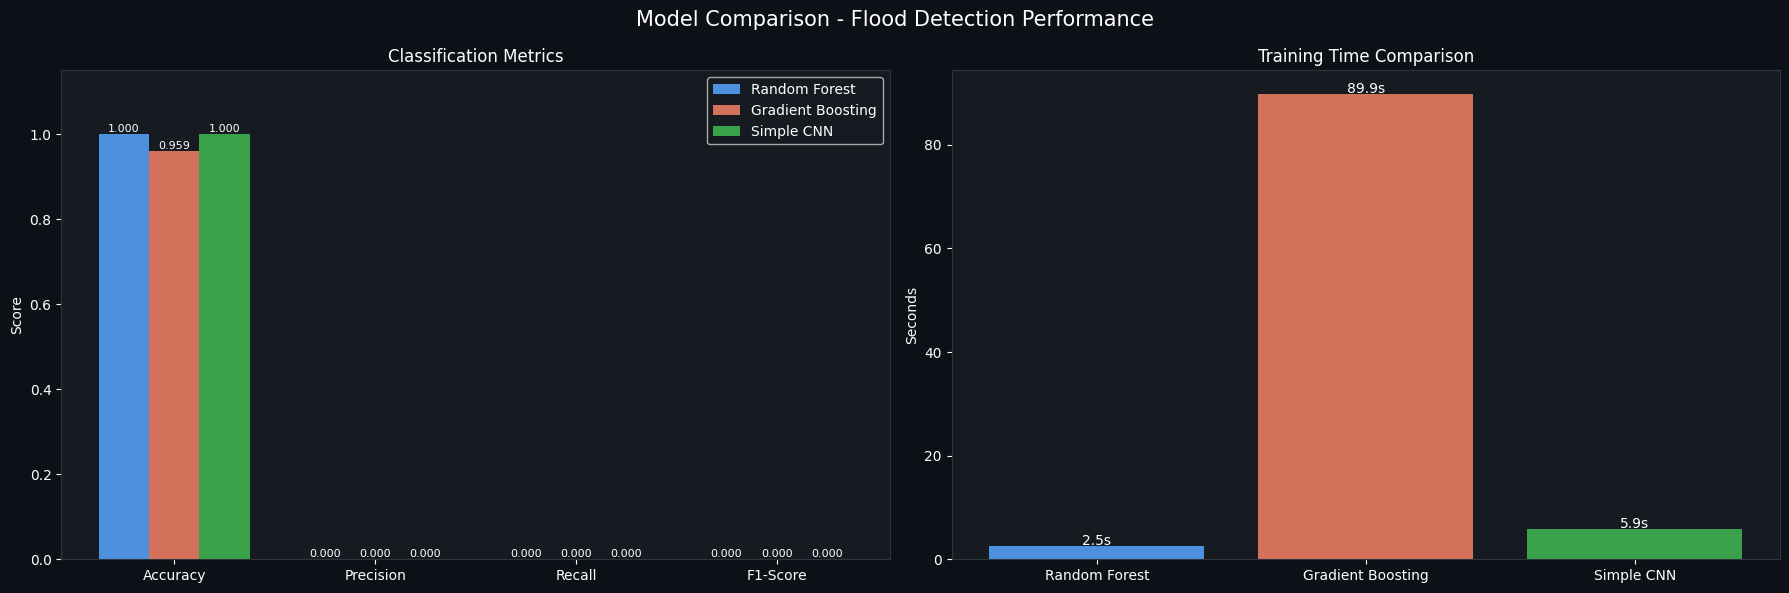

In [4]:
df = pd.DataFrame(results).T
print('=== Model Comparison Results ===')
print(df.to_string())

metric_cols = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
colors = ['#58a6ff', '#f78166', '#3fb950']
x = np.arange(len(metric_cols))
width = 0.25

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fig.suptitle('Model Comparison - Flood Detection Performance', fontsize=15, color='white')

for i, (m_name, color) in enumerate(zip(results.keys(), colors)):
    vals = [results[m_name][m] for m in metric_cols]
    bars = axes[0].bar(x + i * width, vals, width, label=m_name, color=color, alpha=0.85)
    for bar, v in zip(bars, vals):
        axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005, f'{v:.3f}', ha='center', fontsize=8)

axes[0].set_xticks(x + width)
axes[0].set_xticklabels(metric_cols)
axes[0].set_ylim(0, 1.15)
axes[0].set_title('Classification Metrics')
axes[0].legend()
axes[0].set_ylabel('Score')

m_names = list(results.keys())
times = [results[m]['Train Time (s)'] for m in m_names]
bars2 = axes[1].bar(m_names, times, color=colors, alpha=0.85)
for bar, t in zip(bars2, times):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2, f'{t:.1f}s', ha='center', fontsize=10)
axes[1].set_title('Training Time Comparison')
axes[1].set_ylabel('Seconds')

plt.tight_layout()
plt.savefig(os.path.join(ROOT_DIR, 'data/model_comparison.png'), dpi=120, bbox_inches='tight', facecolor='#0d1117')
plt.show()
